# Weighted Gene Correlation Network Analysis

> Weighted Gene Correlation Network Analysis (WGCNA)
> 
> Objective: To successfully run network and module construction with gene expression measurements and to use that network to identify potential candidate genes associated with measured phenotypes.
> 1. Identify clusters of similarly expressed genes
> 2. Identify highly connected ‘hub’ genes
> 3. Relate clusters (modules) of genes to one another
> 4. Relate gene expression to external sample traits
> - Zhang, Bin and Horvath, Steve. "A General Framework for Weighted Gene Co-Expression Network Analysis" Statistical Applications in Genetics and Molecular Biology, vol. 4, no. 1. https://doi.org/10.2202/1544-6115.1128.
> - Langfelder, P., Horvath, S. WGCNA: an R package for weighted correlation network analysis. BMC Bioinformatics 9, 559 (2008). https://doi.org/10.1186/1471-2105-9-559.
> - Peter Langfelder, Bin Zhang, Steve Horvath, Defining clusters from a hierarchical cluster tree: the Dynamic Tree Cut package for R, Bioinformatics, Volume 24, Issue 5, March 2008, Pages 719–720, https://doi.org/10.1093/bioinformatics/btm563
> 

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(WGCNA))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(SummarizedExperiment))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/database/UCSC_Xena/TCGA-COAD"

In [3]:
eSet <- readRDS(file.path(data_dir, "TCGA-COAD.star_counts.rds"))
eSet

class: SummarizedExperiment 
dim: 21284 514 
metadata(0):
assays(2): counts TPM
rownames(21284): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288670.1 ENSG00000288675.1
rowData names(3): basepairs gene_name gene_type
colnames(514): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(13): Patient_ID Gender ... Vital_Status Group

In [4]:
# eSet[, eSet$Group == "Tumor"]
norm_mat <- assay(eSet, "TPM") 

In [5]:
# Filtering of samples and genes with too many missing entries.
gsg <- norm_mat |> t() |> goodSamplesGenes()
summary(gsg)

 Flagging genes and samples with too many missing values...
  ..step 1


            Length Class  Mode   
goodGenes   21284  -none- logical
goodSamples   514  -none- logical
allOK           1  -none- logical

## [WGCNA](https://cran.r-project.org/web/packages/WGCNA/index.html)

In [6]:
# # Filtering
# if (!gsg$allOK) {
#     # Identifies and prints outlier genes
#     if (sum(!gsg$goodGenes) > 0) {
#         paste(
#             "Removing genes:", 
#             paste(names(mat)[!gsg$goodGenes], collapse = ",")) |>
#             printFlush()
#     }
#     # Identifies and prints oulier samples
#     if (sum(!gsg$goodSamples) > 0) {
#         paste(
#             "Removing samples:", 
#             paste(rownames(mat)[!gsg$goodSamples], collapse = ",")) |> 
#             printFlush()
#     }
#     mat = mat[gsg$goodSamples, gsg$goodGenes]
# }

### 1). Gene Co-expression Network Construction

> - Pairwise Gene Co-expression similarity
>     - Unsigned Networks
>         - $sab = |cor(a, b)|$
>     - Signed Networks
>         - $sab = 0.5 + 0.5 ∗ cor(a, b)$
>     - Signed Hybrid Networks
>         - $sab = cor(a, b) = {cor\ if\ cor>0,\ 0\ if\ cor<=0}$
> - Adjacency: Pairwise connection
>     - Unweighted Networks
>         - $aij = signum(sij, τ) = {1\ if\ sij≥τ, 0\ if\ sij<τ}$
>     - Weighted Networks
>         - Determining the Soft Power Threshold: it is the spt that retains the highest mean connectivity while reaching an R^2 value above 0.80.
>         - $aij = power(sij, β) = |sij|^β$
> - Calling the Adjacency Function

In [7]:
spt <- norm_mat |> t() |> 
    pickSoftThreshold(networkType = "signed")

Warning message:
“executing %dopar% sequentially: no parallel backend registered”


   Power SFT.R.sq  slope truncated.R.sq mean.k. median.k. max.k.
1      1  0.25900  6.370          0.853 11600.0  11500.00  13400
2      2  0.10700  1.910          0.718  6540.0   6380.00   8910
3      3  0.00275  0.187          0.581  3830.0   3600.00   6330
4      4  0.14700 -0.871          0.568  2330.0   2070.00   4730
5      5  0.55000 -1.380          0.734  1480.0   1220.00   3670
6      6  0.76000 -1.530          0.833   972.0    734.00   2940
7      7  0.83000 -1.570          0.865   663.0    454.00   2450
8      8  0.85300 -1.580          0.874   469.0    288.00   2080
9      9  0.87000 -1.550          0.885   342.0    187.00   1790
10    10  0.87800 -1.520          0.891   257.0    124.00   1560
11    12  0.89800 -1.450          0.911   155.0     57.50   1220
12    14  0.90600 -1.400          0.926   101.0     28.60    988
13    16  0.90700 -1.380          0.933    69.9     15.00    826
14    18  0.87900 -1.400          0.918    50.3      8.21    704
15    20  0.86600 -1.400 

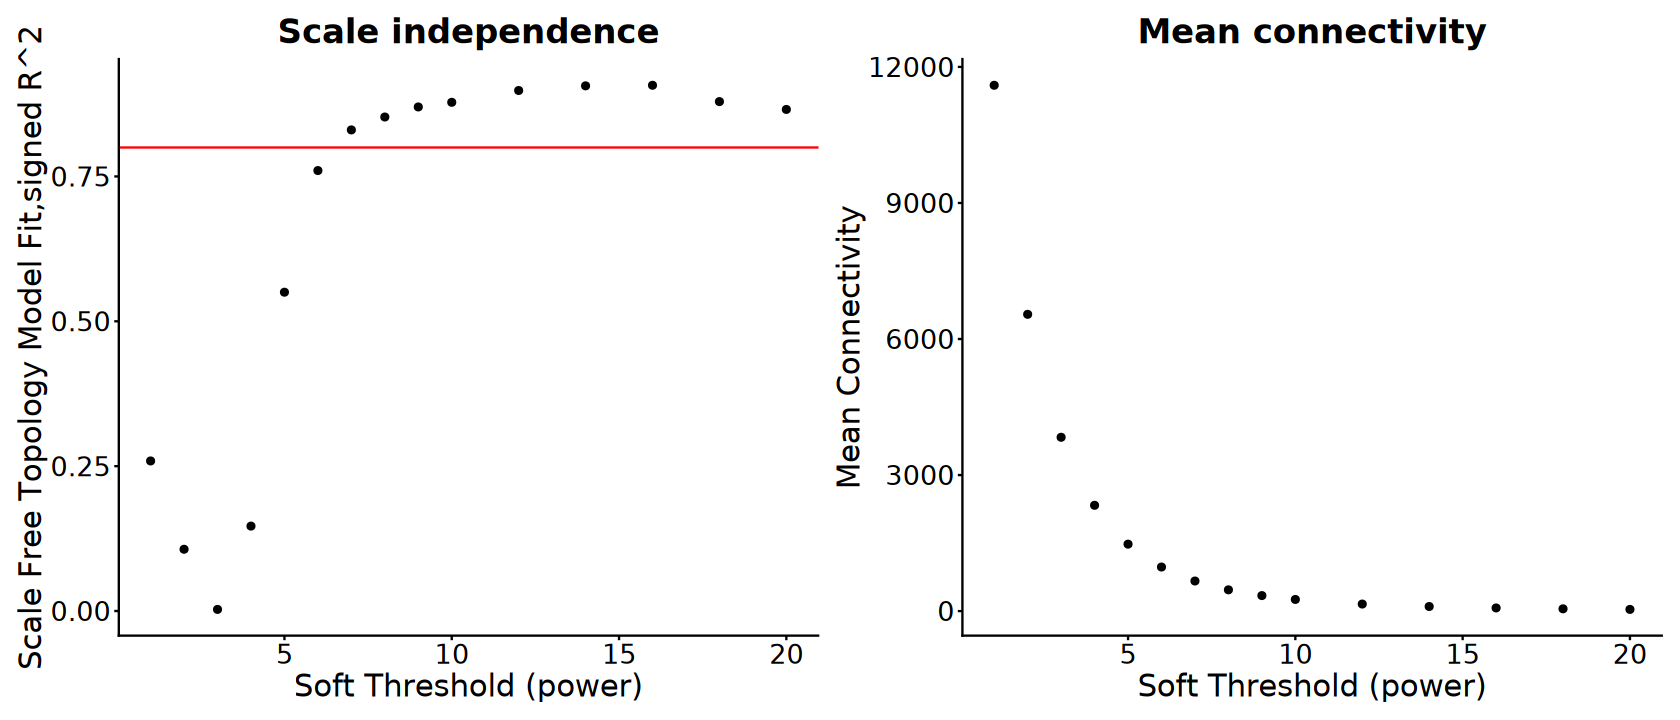

In [8]:
p1 <- ggplot(spt$fitIndices, aes(x = Power, y = SFT.R.sq)) +
    geom_point() + 
    geom_hline(yintercept = 0.8, color = "red") +
    labs(
        title = "Scale independence", x = "Soft Threshold (power)",
        y = "Scale Free Topology Model Fit,signed R^2") +
    theme_classic() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

p2 <- ggplot(spt$fitIndices, aes(x = Power, y = mean.k.)) +
    geom_point() + 
    labs(
        title = "Mean connectivity", x = "Soft Threshold (power)",
        y = "Mean Connectivity") +
    theme_classic() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

options(repr.plot.width = 14, repr.plot.height = 6)
p1 + p2

In [9]:
connectivity <- norm_mat |> t() |>
    softConnectivity(type = "signed", power = spt$powerEstimate)

 softConnectivity: FYI: connecitivty of genes with less than 172 valid samples will be returned as NA.
 ..calculating connectivities.. 


scaleFreeRsquared,slope
<dbl>,<dbl>
0.83,-1.58


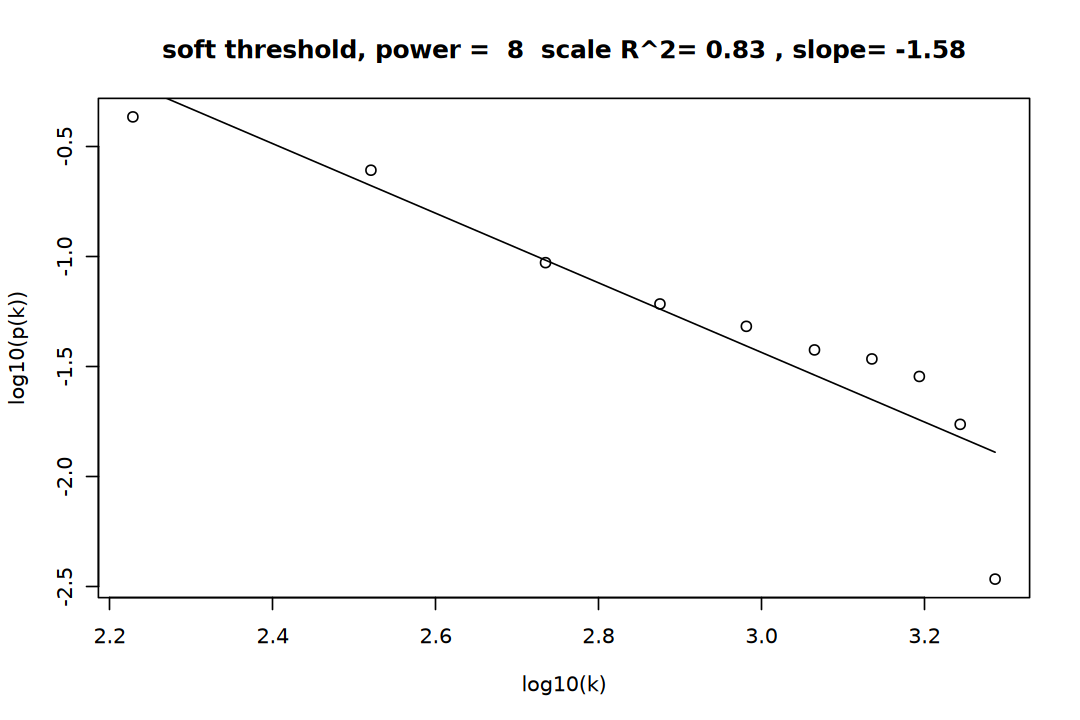

In [10]:
options(repr.plot.width = 9, repr.plot.height = 6)

scaleFreePlot(connectivity, main = paste(
    "soft threshold, power = ", spt$powerEstimate))

In [11]:
idx <- data.table::frank(
    connectivity, ties.method = "first") <= 3600

In [12]:
# Calculate network adjacency
adjacency <- norm_mat[idx, ] |> t() |> 
    adjacency(type = "signed", power = spt$powerEstimate)

dim(adjacency)
adjacency[1:6, 1:6]

[1] 3600 3600

,ENSG00000000005.6,ENSG00000001617.12,ENSG00000002079.14,ENSG00000002330.14,ENSG00000002587.10,ENSG00000002726.21
ENSG00000000005.6,1.000000000,0.002215476,0.002978130,0.002397186,0.001692841,0.002884033
ENSG00000001617.12,0.002215476,1.000000000,0.003010545,0.005728247,0.009707238,0.003189924
ENSG00000002079.14,0.002978130,0.003010545,1.000000000,0.003574136,0.024501331,0.002506109
ENSG00000002330.14,0.002397186,0.005728247,0.003574136,1.000000000,0.007122177,0.008441125
ENSG00000002587.10,0.001692841,0.009707238,0.024501331,0.007122177,1.000000000,0.001673669
ENSG00000002726.21,0.002884033,0.003189924,0.002506109,0.008441125,0.001673669,1.000000000


### 2). Module Definition

In [13]:
# # Calculate topological overlap matrix similarity
# TOM_simi <- TOMsimilarity(adjacency)

# Calculate topological overlap matrix dissimilarity
# TOM_diss <- 1 - TOM_simi
TOM_diss <- TOMdist(adjacency)

..connectivity..
..matrix multiplication (system BLAS)..
..normalization..
..done.


In [14]:
# Hierarchical clustering with the TOM matrix
TOM_hc <- hclust(as.dist(TOM_diss), method = "average") 

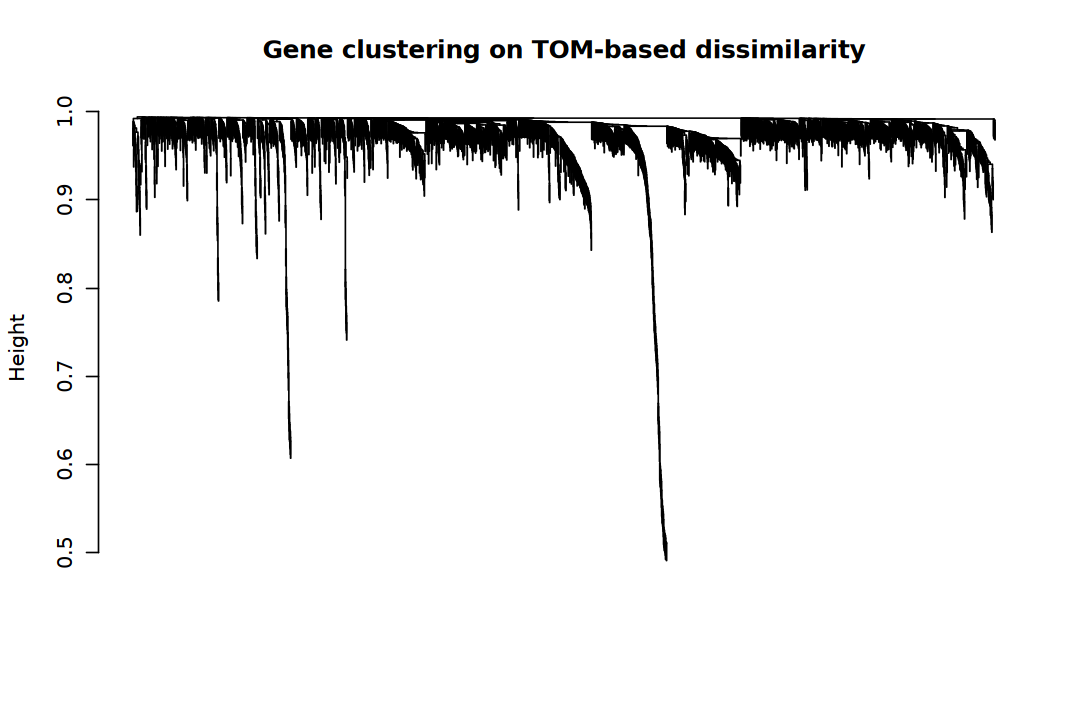

In [15]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(
    TOM_hc, labels = FALSE, hang = 0.04, xlab = "", sub = "",
    main = "Gene clustering on TOM-based dissimilarity")

In [16]:
module_colors <- data.frame(
    Module = cutreeStaticColor(
        TOM_hc, cutHeight = 0.9, minSize = 50))

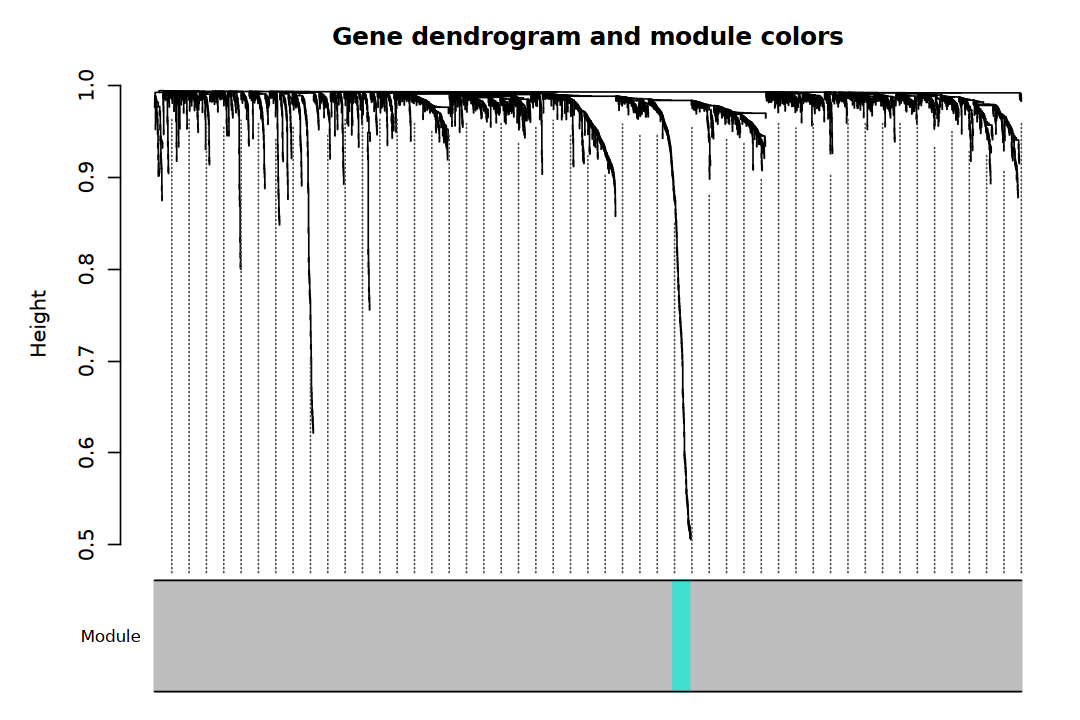

In [17]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDendroAndColors(
    TOM_hc, module_colors, "Module", 
    dendroLabels = FALSE, hang = 0.01,
    addGuide = TRUE, guideHang = 0.05,
    main = "Gene dendrogram and module colors")

In [ ]:
# Dynamic Tree Cut
modules <- cutreeDynamic(
    dendro = TOM_hc, distM = TOM_diss, deepSplit = 2, 
    pamRespectsDendro = FALSE, minClusterSize = 50)

table(modules)

module_colors <- labels2colors(modules)

 ..cutHeight not given, setting it to 0.993  ===>  99% of the (truncated) height range in dendro.
 ..done.


modules
  1   2   3   4   5   6   7   8 
889 734 599 574 274 254 211  65 

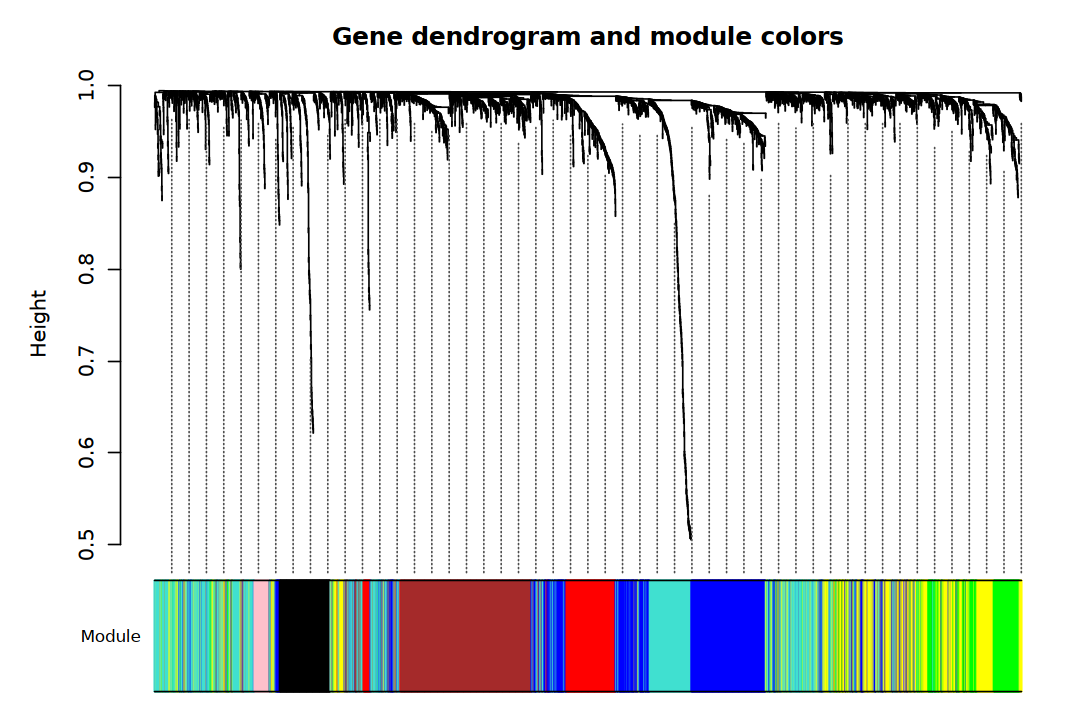

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDendroAndColors(
    TOM_hc, module_colors, "Module", 
    dendroLabels = FALSE, hang = 0.01,
    addGuide = TRUE, guideHang = 0.05,
    main = "Gene dendrogram and module colors")

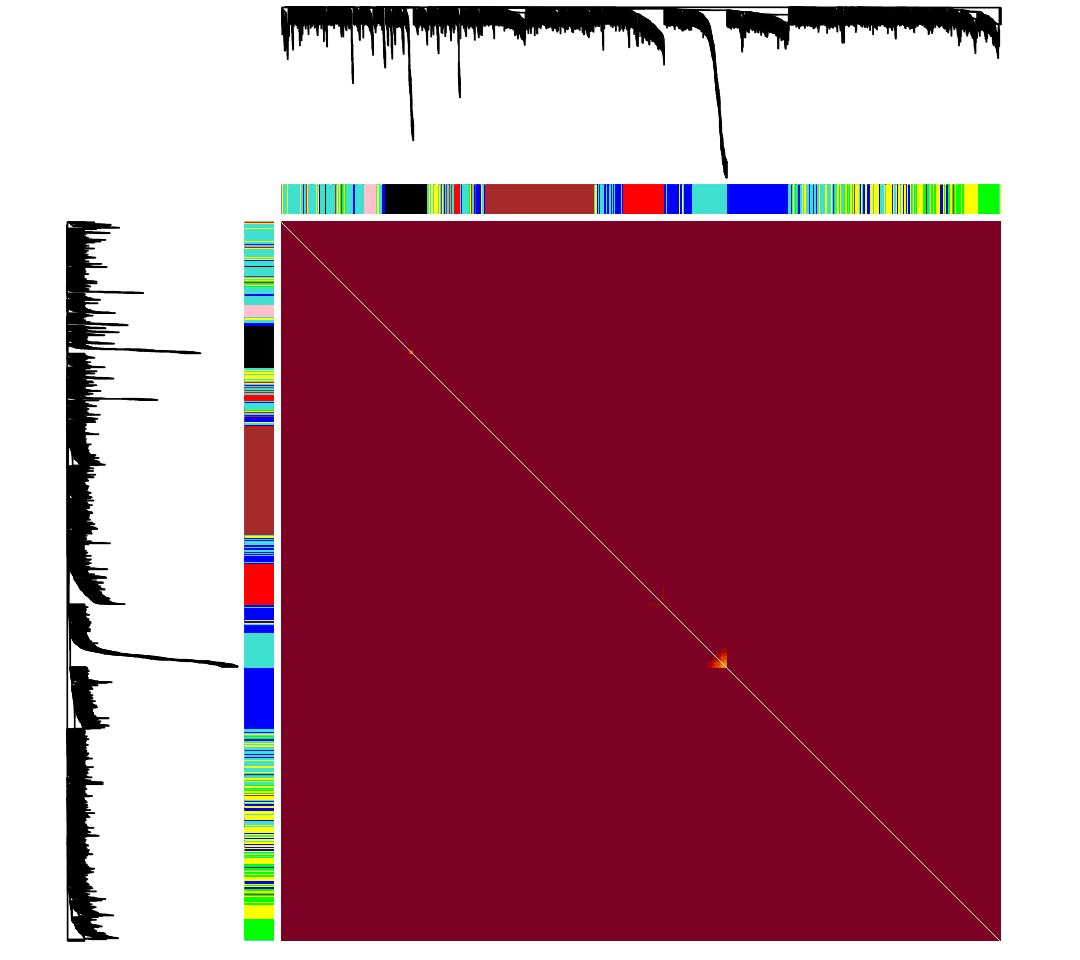

In [20]:
options(repr.plot.width = 9, repr.plot.height = 8)

TOMplot(TOM_diss, TOM_hc, module_colors) 

In [21]:
# Calculates module eigengenes of modules
ME_list <- norm_mat[rownames(adjacency), ] |> t() |> 
    moduleEigengenes(colors = module_colors)

In [22]:
MEs <- ME_list$eigengenes
MEs[1:6, 1:6]

,MEblack,MEblue,MEbrown,MEgreen,MEpink,MEred
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TCGA-5M-AAT6-01A,0.040155028,-0.060758122,0.015070328,-0.03405875,0.013077827,0.0080156647
TCGA-AA-3552-01A,0.006153598,0.031896822,-0.008226873,-0.03438351,0.007306029,0.0891333174
TCGA-AA-3867-01A,0.005268629,0.013290102,-0.035052066,-0.04091654,0.001660594,0.0005956832
TCGA-AD-6895-01A,0.067415741,0.007031616,0.139423517,-0.02175808,-0.005068202,-0.0313034651
TCGA-AA-3560-01A,-0.020893045,-0.009112631,0.007040797,0.04420915,-0.022272085,-0.0013555105
TCGA-CM-6676-01A,-0.006349968,0.003162684,-0.034798823,-0.01684504,0.013882599,-0.0344267481


In [23]:
MEs_diss = 1 - cor(MEs, use = "complete")

In [24]:
# Clustering eigengenes
MEs_hc <- hclust(as.dist(MEs_diss), method = "average")

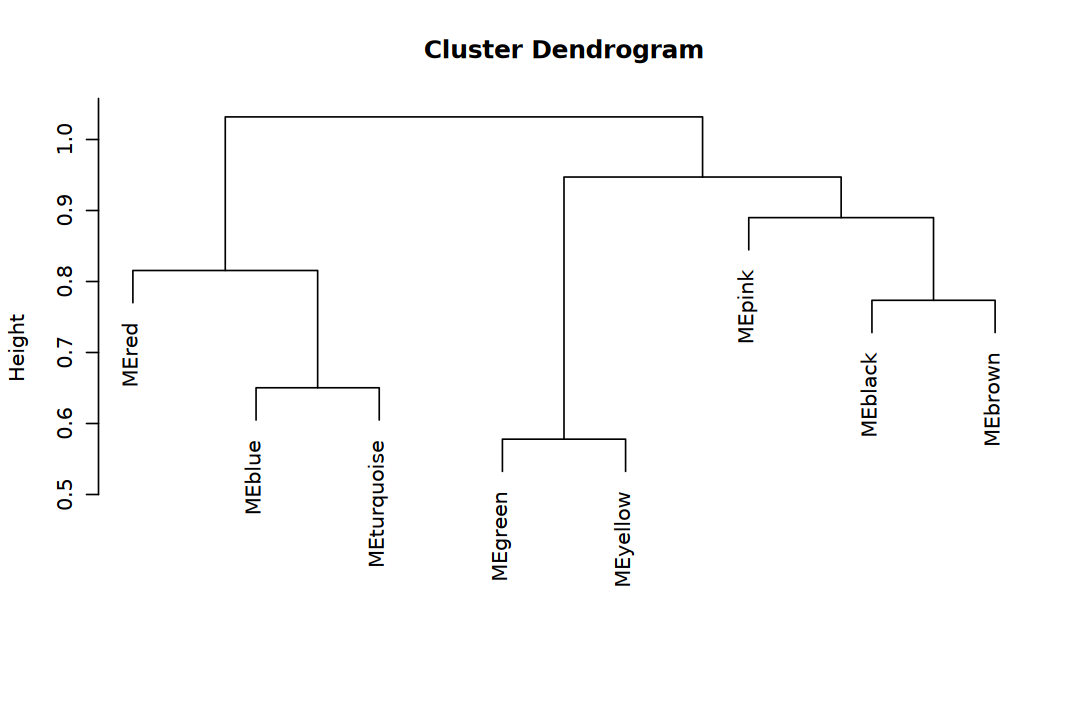

In [25]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(MEs_hc, xlab = "", sub = "")
abline(h = 0.25, col = "red")

In [ ]:
# # Calculation of (signed) eigengene-based connectivity
# tmp <- norm_mat[rownames(adjacency), ] |> t() |> signedKME(datME = MEs)

In [26]:
# Merges modules in gene expression networks
module_merge <- norm_mat[rownames(adjacency), ] |> t() |> 
    mergeCloseModules(module_colors, cutHeight = 0.25)

 mergeCloseModules: Merging modules whose distance is less than 0.25
   Calculating new MEs...


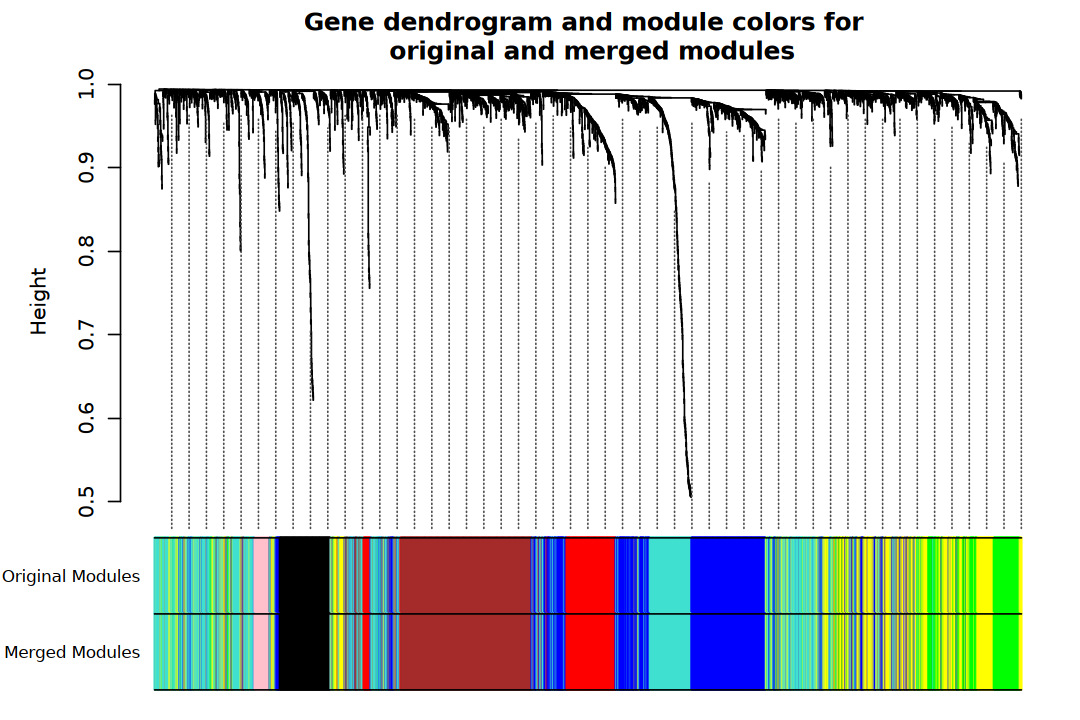

In [27]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDendroAndColors(
    TOM_hc, cbind(module_colors, module_merge$colors), 
    c("Original Modules", "Merged Modules"),
    dendroLabels = FALSE, hang = 0.01,
    addGuide = TRUE, guideHang = 0.05,
    main = "Gene dendrogram and module colors for \n original and merged modules")

### 3). Module-Trait Associations

In [31]:
colnames(colData(eSet))

[1] "Patient_ID"   "Gender"       "Age"          "Disease_Type" "Primary_Site"
 [6] "Sample_Type"  "Tissue_Type"  "AJCC_Stage"   "AJCC_T"       "AJCC_N"      
[11] "AJCC_M"       "Vital_Status" "Group"

In [57]:
# Turn a categorical variable into a set of binary indicators
# binarizeCategoricalVariable(
#     eSet$AJCC_Stage, includePairwise = FALSE, includeLevelVsAll = TRUE)
trait_df <- colData(eSet) |> as.data.frame() |> 
    binarizeCategoricalColumns(
        convertColumns = c("Tissue_Type"), includePairwise = FALSE, 
        includeLevelVsAll = TRUE, dropFirstLevelVsAll = TRUE) |>
    binarizeCategoricalColumns(
        convertColumns = c("AJCC_Stage"), includePairwise = FALSE, 
        includeLevelVsAll = TRUE, dropFirstLevelVsAll = FALSE) |>
    select(where(is.numeric))

In [58]:
head(trait_df)

,Age,Tissue_Type.Tumor.vs.all,AJCC_Stage.Stage I.vs.all,AJCC_Stage.Stage II.vs.all,AJCC_Stage.Stage III.vs.all,AJCC_Stage.Stage IV.vs.all
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TCGA-5M-AAT6-01A,40,1,0,0,0,1
TCGA-AA-3552-01A,85,1,0,0,1,0
TCGA-AA-3867-01A,74,1,0,0,0,1
TCGA-AD-6895-01A,84,1,0,0,1,0
TCGA-AA-3560-01A,72,1,0,0,1,0
TCGA-CM-6676-01A,82,1,1,0,0,0


In [59]:
# Pearson correlation coefficient
module_trait_correlation <- cor(MEs, trait_df, use = "p")
# Calculate the p-value associated with the correlation
module_trait_pvalue <- corPvalueStudent(module_trait_correlation, nrow(MEs))

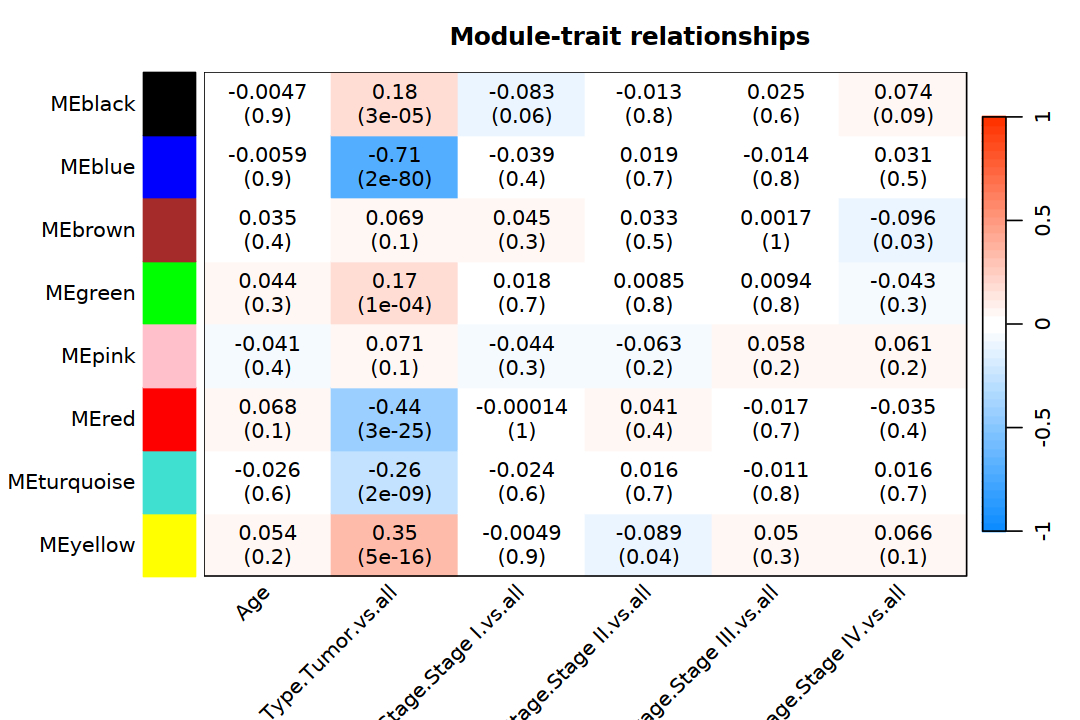

In [60]:
textMatrix = paste(
    signif(module_trait_correlation, 2), "\n(", 
    signif(module_trait_pvalue, 1), ")", sep = "")

dim(textMatrix) = dim(module_trait_correlation)

options(repr.plot.width = 9, repr.plot.height = 6)

par(mar = c(6, 8.5, 3, 1))

labeledHeatmap(
    Matrix = module_trait_correlation,
    xLabels = names(trait_df), yLabels = names(MEs), 
    ySymbols = names(MEs), colorLabels = FALSE, 
    colors = blueWhiteRed(50), textMatrix = textMatrix,
    setStdMargins = FALSE, cex.text = 1, zlim = c(-1,1),
    main = paste("Module-trait relationships"))

In [35]:
# Calculate the module membership and the associated p-values
gene_module_membership <- norm_mat[rownames(adjacency), ] |> t() |> 
    cor(MEs, use = "p") |> as.data.frame()

MM_pvalue <- gene_module_membership |> as.matrix() |> 
    corPvalueStudent(nrow(MEs)) |> as.data.frame()

In [36]:
# Calculate the gene significance and associated p-values
gene_trait_significance <- norm_mat[rownames(adjacency), ] |> t() |> 
    cor(trait_df$Tissue_Type, use = "p") |> as.data.frame()

GS_pvalue <- gene_trait_significance |> as.matrix() |> 
    corPvalueStudent(nrow(MEs)) |> as.data.frame()

In [37]:
module <- "blue"
module_idx <- match(paste0("ME", module), colnames(MEs))
gene_idx <- module_colors == module

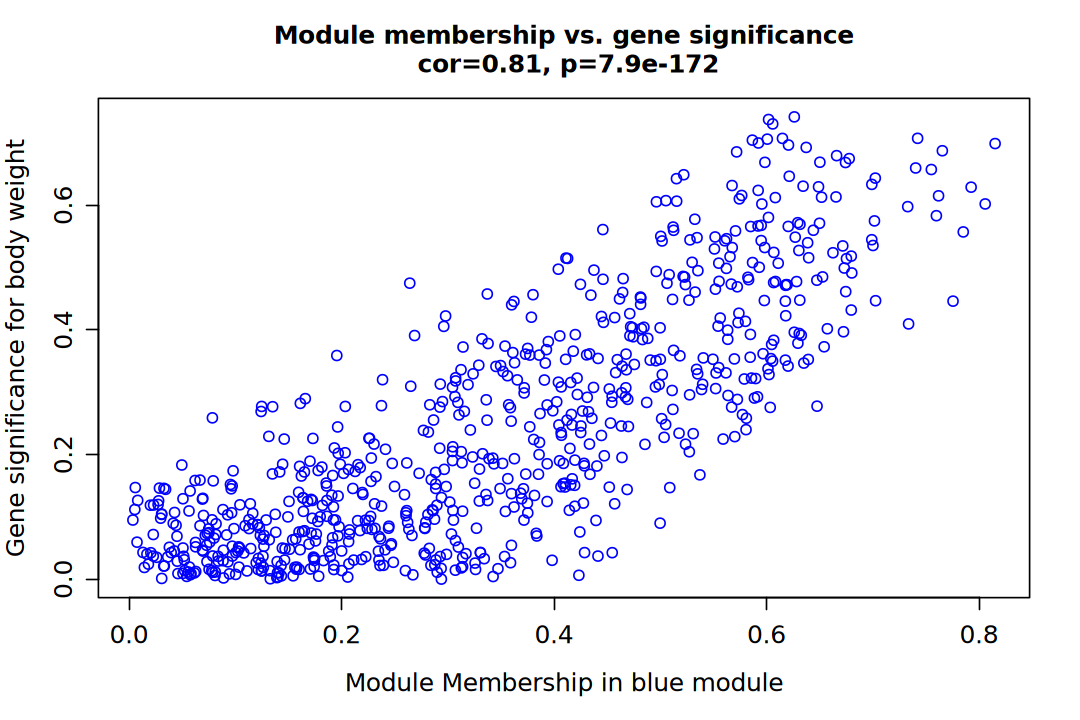

In [38]:
options(repr.plot.width = 9, repr.plot.height = 6)

verboseScatterplot(
    abs(gene_module_membership[gene_idx, module_idx]), 
    abs(gene_trait_significance[gene_idx, 1]),
    xlab = paste("Module Membership in", module, "module"),
    ylab = "Gene significance for body weight",
    main = paste("Module membership vs. gene significance\n"),
    cex.main = 1.2, cex.lab = 1.2, cex.axis = 1.2, col = module)

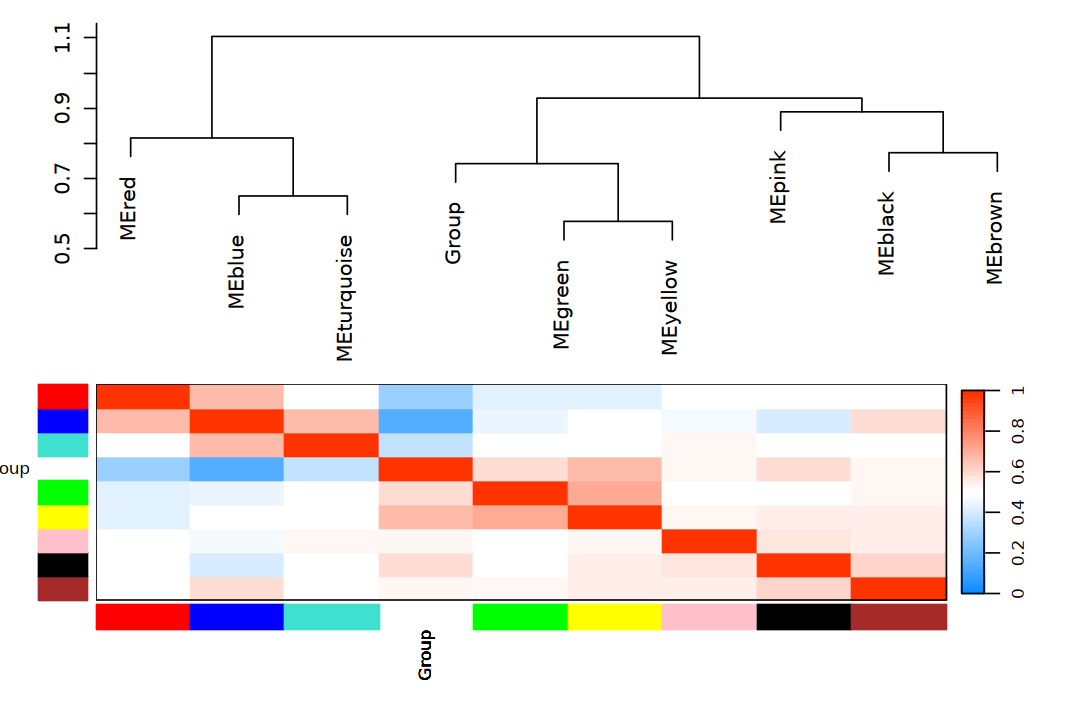

In [ ]:
# Isolate group from the clinical traits
group = as.data.frame(trait_df$Tissue_Type);
names(group) = "Group"
# Add the group to existing module eigengenes
MET <- orderMEs(cbind(MEs, group))
# Plot the relationships among the eigengenes and the trait
plotEigengeneNetworks(
    MET, "", marDendro = c(0,4, 1,2), marHeatmap = c(5, 4, 1, 2), 
    cex.lab = 0.8, xLabelsAngle = 90)

### 4. 

## [PyWGCNA](https://github.com/mortazavilab/PyWGCNA)

> PyWGCNA is a Python library designed to do weighted correlation network analysis (WGCNA). It can be used for finding clusters (modules) of highly correlated genes, for summarizing such clusters using the module eigengene, for relating modules to one another and to external sample traits (using eigengene network methodology), and for calculating module membership measures.
> - Narges Rezaie, Farilie Reese, Ali Mortazavi, PyWGCNA: a Python package for weighted gene co-expression network analysis, Bioinformatics, Volume 39, Issue 7, July 2023, btad415, https://doi.org/10.1093/bioinformatics/btad415

## [hdWGCNA](https://github.com/smorabit/hdWGCNA)

> hdWGCNA is an R package for performing weighted gene co-expression network analysis (WGCNA) in high dimensional transcriptomics data such as single-cell RNA-seq or spatial transcriptomics.
> - Morabito S, Reese F, Rahimzadeh N. et al. hdWGCNA identifies co-expression networks in high-dimensional transcriptomics data. Cell Reports Methods, 2023; 3

# Reference

> 1. [Hovarth’s original Tutorial (Failure)](https://horvath.genetics.ucla.edu/html/CoexpressionNetwork/Rpackages/WGCNA/Tutorials/)
> 2. [Weighted Gene Co-expression Network Analysis R Tutorial](https://gds-yazarlab.bilkent.edu.tr/wp-content/uploads/GBMTutorialHorvath.pdf)
> 3. [Victoria French et al. WGCNA tutorial, 2021](https://fuzzyatelin.github.io/bioanth-stats/module-F21-Group1/module-F21-Group1.html)
> 4. [Peter Langfelder Blog](https://peterlangfelder.com/) 
> 5. Yu, P., He, X., Baer, M. et al. Plant flavones enrich rhizosphere Oxalobacteraceae to improve maize performance under nitrogen deprivation. Nat. Plants 7, 481–499 (2021). https://doi.org/10.1038/s41477-021-00897-y.